# 📊 Trabajo Práctico \- Análisis Exploratorio de Datos \(EDA\)

## Materia: Desarrollo de Sistemas de Inteligencia Artificial

## Grupo N° 4

### Integrantes del grupo:

Alba Rotela \- Dataset: \[properati\]
Rodrigo Godoy \- Dataset: \[Trending YouTube Video Statistics\]
Kevin Gutierrez \- Dataset: \[megaGymDataset\.csv\]
Jessica Lopez \- Dataset: \[netflix\_titles\]
Nicolás Galarza Vázquez \- Dataset: \[Catálogo E\-commerce Textil y Hogar\]


# PRIMERA ENTREGA

## 👉🏻 Consigna

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

## 🔍 Introducción

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

# 📁 Dataset 1 – Mercado Inmobiliario \(Integrante: Rotela, Alba\)

## 📝 Descripción del Dataset

Registro masivo de publicaciones de venta y alquiler de propiedades en Argentina\. Incluye datos geográficos \(provincia, barrio\), características físicas del inmueble \(ambientes, m² totales y cubiertos\) y variables económicas \(precio en ARS y USD\)\.

## Importación de Librerías

Se importan las librerías necesarias para la manipulación de datos \(pandas\) y la generación de gráficos \(matplotlib y seaborn\), configurando el estilo visual\.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Las librerías quedaron correctamente cargadas en el entorno virtual de Deepnote, listas para procesar el archivo\.

## 1\. Carga y exploración de datos

### Carga de datos e inspección de dimensiones

Lectura del conjunto de datos desde el archivo almacenado en el panel de archivos de Deepnote e inspección de sus dimensiones iniciales \(cantidad total de filas y columnas\)\.

In [2]:
df_properati = pd.read_csv('properati.csv')

print(f"Filas: {df_properati.shape[0]} | Columnas: {df_properati.shape[1]}")

Filas: 2600 | Columnas: 10


El conjunto de datos cargado registra 2600 filas y 10 columnas\.

### Completar

Despliegue de las primeras cinco filas de la tabla para verificar la correcta disposición de los campos y el formato de los datos\.

In [3]:
df_properati.head()

,operation,property_type,place_name,state_name,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,rooms,expenses,lat
0,sell,house,Punilla,Córdoba,130000.00,NaN,185.0,5.0,NaN,-31.447378
1,sell,apartment,Villa Urquiza,Capital Federal,109000.00,NaN,43.0,1.0,NaN,-34.579461
2,sell,apartment,Villa Urquiza,Capital Federal,89900.00,NaN,38.0,1.0,NaN,-34.579461
3,sell,house,Córdoba,Córdoba,48443.11,NaN,193.0,NaN,NaN,NaN
4,sell,apartment,San Telmo,Capital Federal,80000.00,NaN,47.0,3.0,NaN,-34.622790


Se confirma la presencia de variables cuantitativas \(precios, superficies, ambientes\) y variables cualitativas \(barrios, tipo de propiedad\)\.

### Inspección de tipos de datos y valores nulos

Revisión de los tipos de datos asignados a cada columna por Pandas y detección inicial de registros ausentes\.

In [4]:
df_properati.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2600 entries, 0 to 2599
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   operation              2600 non-null   object 
 1   property_type          2600 non-null   object 
 2   place_name             2600 non-null   object 
 3   state_name             2600 non-null   object 
 4   price_aprox_usd        2600 non-null   float64
 5   surface_total_in_m2    1915 non-null   float64
 6   surface_covered_in_m2  1926 non-null   float64
 7   rooms                  1531 non-null   float64
 8   expenses               196 non-null    float64
 9   lat                    1913 non-null   float64
dtypes: float64(6), object(4)
memory usage: 203.3+ KB


Se verifica la estructura técnica de las variables, identificando la presencia de campos numéricos, categóricos y el conteo de datos faltantes por columna\.

### Resumen estadístico descriptivo

Cálculo de los principales indicadores estadísticos \(media, desviación estándar, mínimos, cuartiles y máximos\) para las columnas numéricas\.

In [5]:
df_properati.describe()

,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,rooms,expenses,lat
count,2.600000e+03,1915.000000,1926.000000,1531.00000,196.000000,1913.000000
mean,2.249972e+05,454.255875,129.190550,2.83083,4303.198980,-34.572051
std,2.529540e+05,4750.480581,165.429979,1.62118,11876.655668,2.163656
min,5.348370e+03,0.000000,0.000000,1.00000,1.000000,-54.818695
25%,8.913043e+04,52.000000,46.000000,2.00000,967.500000,-34.651082
50%,1.480000e+05,101.000000,77.000000,3.00000,2300.000000,-34.577295
75%,2.600000e+05,300.000000,167.750000,4.00000,4500.000000,-32.954395
max,3.600000e+06,200000.000000,4300.000000,18.00000,159000.000000,-24.773643


Se obtienen las métricas descriptivas centrales sobre las variables cuantitativas del conjunto de datos\.

## 2\. Visualizaciones y análisis

### Gráfico 1: Histograma de distribución del precio en USD

Representación gráfica de la frecuencia de publicación de los inmuebles según su precio en dólares, acotando la muestra a valores inferiores a USD 500\.000 para analizar la concentración central de los datos\.

In [6]:
df_precios = df_properati[df_properati['price_aprox_usd'] < 500000]

plt.figure(figsize=(9, 4))
sns.histplot(
    df_precios['price_aprox_usd'], 
    bins=40, 
    kde=True, 
    color='#005b96', 
    edgecolor='black'
)
plt.title('Distribución de Precios de Venta (USD)')
plt.xlabel('Precio (USD)')
plt.ylabel('Frecuencia')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

<Figure size 900x400 with 1 Axes>

📌 La distribución del precio muestra que la mayor parte de la oferta inmobiliaria se agrupa en el rango de los USD 50\.000 a USD 180\.000, disminuyendo la cantidad de propiedades en los valores superiores\.

### Gráfico 2: Dispersión entre superficie cubierta y precio por tipo de propiedad

Visualización de la relación entre la superficie cubierta en m2 y el precio de venta en USD para inmuebles de tipo Departamento, Casa y PH\.

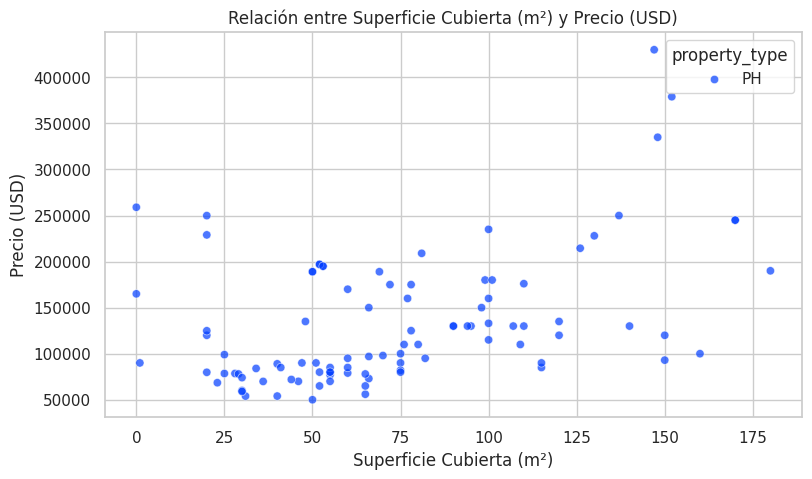

In [7]:
df_filtrado = df_properati[
    (df_properati['property_type'].isin(['Departamento', 'Casa', 'PH'])) &
    (df_properati['surface_covered_in_m2'] < 300) &
    (df_properati['price_aprox_usd'] < 600000)
]

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_filtrado, 
    x='surface_covered_in_m2', 
    y='price_aprox_usd', 
    hue='property_type', 
    palette='bright', 
    alpha=0.7
)
plt.title('Relación entre Superficie Cubierta (m²) y Precio (USD)')
plt.xlabel('Superficie Cubierta (m²)')
plt.ylabel('Precio (USD)')
plt.ticklabel_format(style='plain', axis='y')
plt.show()

📌 Se observa una asociación positiva general donde mayor metraje cubierto se acompaña de un mayor precio\. Los departamentos se concentran en metrajes más reducidos en comparación con las casas\.

## 3\. Observaciones generales

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

- Patrones observados: La mayoría de los inmuebles están agrupados en los valores de entre 50\.000 y 180\.000 dólares\. Se ve una relación lógica entre el tamaño y el valor: a más metros cuadrados cubiertos, el precio sube\. Además, los departamentos suelen tener menos superficie que las casas, pero su precio por metro cuadrado termina siendo más alto\.

- Calidad de los datos: En general la base está bastante bien para arrancar\. Lo positivo es que la columna de precios no tiene datos faltantes\. Al ser información real bajada de un sitio web, es normal encontrar algunos vacíos en columnas secundarias \(como expensas o superficie total\) y varios precios o metrajes muy altos que se salen del promedio\.

- Variables más interesantes:

price\_aprox\_usd: Es el dato clave porque marca el valor en dólares de cada publicación\.

surface\_covered\_in\_m2: Es la característica física que más influye a la hora de entender los cambios en el precio\.

property\_type y place\_name: Son muy útiles para comparar los datos según el tipo de vivienda \(casa, departamento, PH\) y la zona donde están ubicadas\.

# 📁 Dataset 2 – \[Trending YouTube Video Statistics\] \(Integrante: Rodrigo Godoy\)

## 📝 Descripción del Dataset

Este dataset contiene información sobre videos de YouTube que fueron tendencia\.
Incluye datos como visualizaciones, likes, comentarios, categorías y canales\.

## Importación de Librerías

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1\. Carga y exploración de datos

### Carga y revisión de valores

Se cargará y revisara que los valores de dimensión de columnas y filas cumpla con los requisitos

In [9]:
df_rodrigo = pd.read_csv("USvideos.csv")

print("Filas y columnas:", df_rodrigo.shape)

Filas y columnas: (40949, 16)


De esta manera se verifica que se cumple con los requisitos de filas y columnas

### Visualización inicial

Se muestran las primeras filas del dataset para observar cómo están organizados los datos\.

In [10]:
df_rodrigo.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


Se puede observar la estructura de los registros y los diferentes datos que contiene cada columna\.

### Información de las variables

Se revisan las columnas y sus tipos de datos\.

In [11]:
df_rodrigo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   video_id                40949 non-null  object
 1   trending_date           40949 non-null  object
 2   title                   40949 non-null  object
 3   channel_title           40949 non-null  object
 4   category_id             40949 non-null  int64 
 5   publish_time            40949 non-null  object
 6   tags                    40949 non-null  object
 7   views                   40949 non-null  int64 
 8   likes                   40949 non-null  int64 
 9   dislikes                40949 non-null  int64 
 10  comment_count           40949 non-null  int64 
 11  thumbnail_link          40949 non-null  object
 12  comments_disabled       40949 non-null  bool  
 13  ratings_disabled        40949 non-null  bool  
 14  video_error_or_removed  40949 non-null  bool  
 15  de

Se pueden identificar los tipos de datos de cada columna y comprobar la cantidad de valores no nulos\.

### Valores faltantes

Se revisan los datos faltantes de cada columna para identificar posibles registros incompletos\.

In [12]:
df_rodrigo.isnull().sum()

video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
description               570
dtype: int64

La mayoría de las columnas no presenta datos faltantes\. Solo la columna description tiene 570 valores ausentes\.

### Resumen estadístico 

Se analizan los datos numéricos del dataset para conocer sus principales características\.

In [13]:
df_rodrigo.describe()

,category_id,views,likes,dislikes,comment_count
count,40949.000000,4.094900e+04,4.094900e+04,4.094900e+04,4.094900e+04
mean,19.972429,2.360785e+06,7.426670e+04,3.711401e+03,8.446804e+03
std,7.568327,7.394114e+06,2.288853e+05,2.902971e+04,3.743049e+04
min,1.000000,5.490000e+02,0.000000e+00,0.000000e+00,0.000000e+00
25%,17.000000,2.423290e+05,5.424000e+03,2.020000e+02,6.140000e+02
50%,24.000000,6.818610e+05,1.809100e+04,6.310000e+02,1.856000e+03
75%,25.000000,1.823157e+06,5.541700e+04,1.938000e+03,5.755000e+03
max,43.000000,2.252119e+08,5.613827e+06,1.674420e+06,1.361580e+06


La tabla muestra la cantidad de datos, el promedio, los valores mínimos y máximos, la mediana y los cuartiles de las variables numéricas\.

## 2\. Visualizaciones y análisis

### Comentarios habilitados y deshabilitados

Se analiza la cantidad de videos que tienen los comentarios habilitados o deshabilitados\.

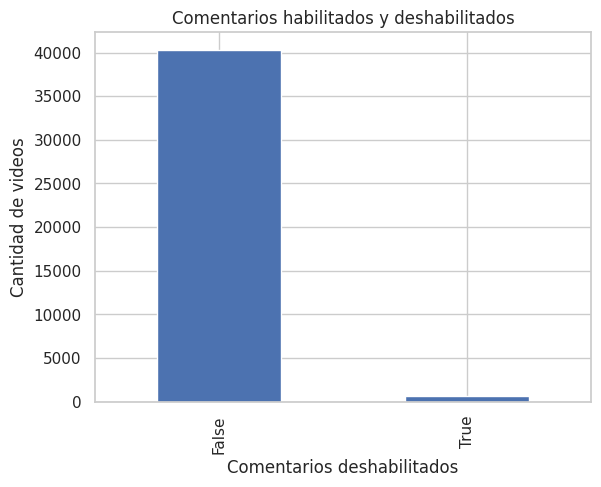

In [14]:
comentarios = df_rodrigo["comments_disabled"].value_counts()

comentarios.plot(kind="bar")

plt.title("Comentarios habilitados y deshabilitados")
plt.xlabel("Comentarios deshabilitados")
plt.ylabel("Cantidad de videos")
plt.show()

La mayoría de los videos tiene los comentarios habilitados, mientras que una pequeña cantidad los tiene deshabilitados\.

### Videos por categoría

Se analiza la cantidad de videos que pertenece a cada categoría del dataset\.

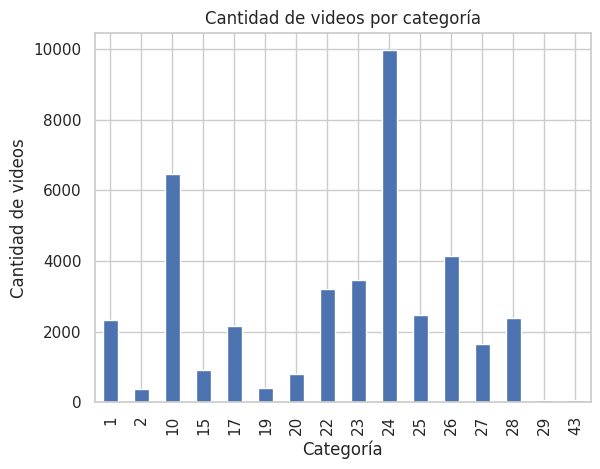

In [15]:
categorias = df_rodrigo["category_id"].value_counts().sort_index()

categorias.plot(kind="bar")

plt.title("Cantidad de videos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de videos")
plt.show()

En el grafico se observa que la cantidad de videos varía según la categoría\.

## 3\. Observaciones generales

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

Patrones observados: En el primer grafico se nota que la gran mayoría de los videos tienen los comentarios habilitados ya que esto influye en los algoritmos y beneficia al ecosistema\. Aquellos videos con comentarios desactivados tienden a ser de contenido dirigido a un publico infantil\.  En el caso de la variedad en cantidad de videos por categoría se entiende que es una herramienta para los creadores de contenido para posicionarse en un nicho especifico\.

 Calidad de datos: Al tratarse de una base amplia, es normal encontrar algunos valores nulos\. Lo positivo es que la gran cantidad de datos permite realizar un análisis más completo y obtener resultados más interesantes\.

Variables Interesantes: Las variables más interesantes son las de vistas, likes y comentarios ya que entre si se pueden relacionar para evaluar la "calidad" del contenido y como rinde, estas variables son las mas importantes para los creadores de contenido ya que cada nicho o publico tiene su "formula" en cuanto a duracion, tematica abordada y como generar interacciones \(opiniones, reacciones, etc\.\)

# 📁 Dataset 3 – \[megaGymDataset\.csv\] \(Integrante: Kevin Gutiérrez\)

## 📝 Descripción del Dataset

El dataset que elegí contiene un conjunto de datos creado para analizar y evaluar los entrenamientos que se pueden realizar en el gimnasio \(o en casa\) para mantenerse saludable\. 

## Importación de Librerías

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

## 1\. Carga y exploración de datos

###  Carga de Dataset

Código para cargar el dataset y mostrar estructura

In [17]:
df = pd.read_csv('megaGymDataset.csv', sep=',')

print("INFORMACIÓN GENERAL DEL DATASET")
print(f"Dimensiones del archivo: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

INFORMACIÓN GENERAL DEL DATASET
Dimensiones del archivo: 2918 filas y 9 columnas.



Se crea una variable con el nombre df, la cual servirá para trabajar con el dataset de ejercicios de gimnasio\. También vemos que podemos visualizar las dimensiones del archivo\.

###  Control de Archivo

Ese bloque de código sirve para hacer un control de calidad rápido y verificar visualmente que el archivo se cargó de forma correcta y organizado\.

In [18]:
df.head()

,Unnamed: 0,Title,Desc,Type,BodyPart,Equipment,Level,Rating,RatingDesc
0,0,Partner plank band row,The partner plank band row is an abdominal exe...,Strength,Abdominals,Bands,Intermediate,0.0,NaN
1,1,Banded crunch isometric hold,The banded crunch isometric hold is an exercis...,Strength,Abdominals,Bands,Intermediate,NaN,NaN
2,2,FYR Banded Plank Jack,The banded plank jack is a variation on the pl...,Strength,Abdominals,Bands,Intermediate,NaN,NaN
3,3,Banded crunch,The banded crunch is an exercise targeting the...,Strength,Abdominals,Bands,Intermediate,NaN,NaN
4,4,Crunch,The crunch is a popular core exercise targetin...,Strength,Abdominals,Bands,Intermediate,NaN,NaN


Tomamos de la base de datos \(df\) y extraemos únicamente las primeras 5 filas, junto con los títulos de tus 9 columnas\.

## 2\. Visualizaciones y análisis

### Distribución de Ejercicios por Grupo Muscular Objetivo

Buscaremos identificar la cantidad de ejercicios que existen para cada musculo, y a su vez realizar un grafico de barras donde podemos visualizar que tipo de musculo o parte del cuerpo tiene mas ejercicios\.

/tmp/ipykernel_540/806074797.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='BodyPart', order=df['BodyPart'].value_counts().index, palette='Blues_r')


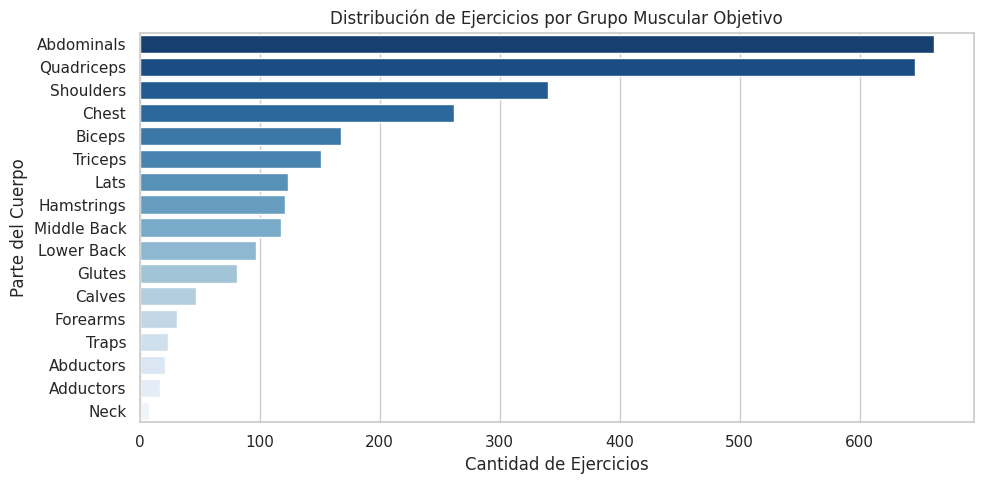

In [19]:
plt.figure()
sns.countplot(data=df, y='BodyPart', order=df['BodyPart'].value_counts().index, palette='Blues_r')
plt.title('Distribución de Ejercicios por Grupo Muscular Objetivo')
plt.xlabel('Cantidad de Ejercicios')
plt.ylabel('Parte del Cuerpo')
plt.tight_layout()
plt.show()

📌 Interpretación del gráfico: Podemos observar que el grupo o músculo que mas ejercicios tiene en este Dataset es el de Abdominales, con mas de 600 ejercicios\.

### Tipos de Equipos y Nivel de Dificultad

Analizaremos 5 de los equipos mas usados para los diferentes ejercicos y a su vez lo distribuiremos segun su nivel de dificultad\.

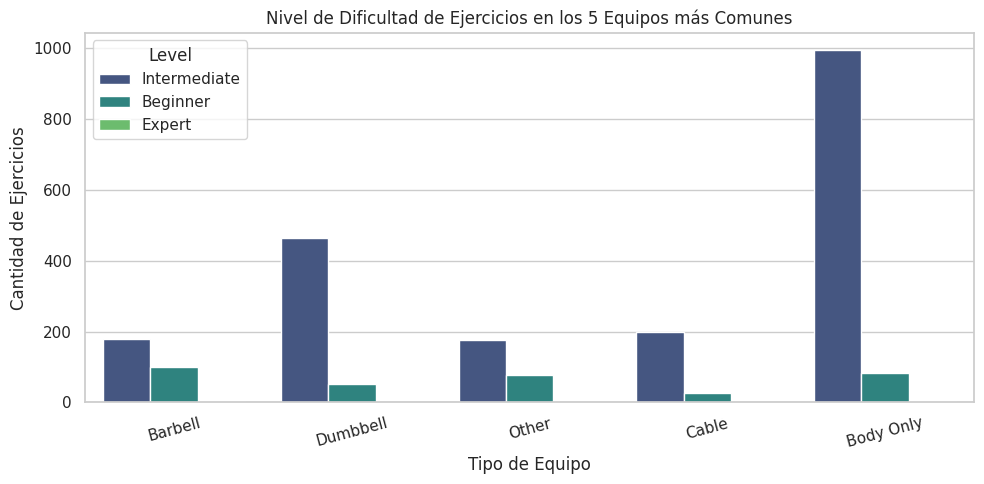

In [20]:
plt.figure()

top_equipment = df['Equipment'].value_counts().head(5).index
df_filtered = df[df['Equipment'].isin(top_equipment)]

sns.countplot(data=df_filtered, x='Equipment', hue='Level', palette='viridis')
plt.title('Nivel de Dificultad de Ejercicios en los 5 Equipos más Comunes')
plt.xlabel('Tipo de Equipo')
plt.ylabel('Cantidad de Ejercicios')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

📌 Interpretación del gráfico: Se puede observar que el equipo que mas se utiliza es Body Only \(Solo el cuerpo\) y que a su vez brinda un nivel de ejercicios de nivel intermedio, en comparación con otros equipos\.

## 3\. Observaciones generales

Luego de analizar este dataset, pude observar que existe una variedad casi infinita de ejercicios y que este tipo de información se mantendrá vigente por mucho tiempo\. Si bien el conjunto de datos es sumamente rico, me encontré con el desafío de que faltan variables numéricas, lo cual podría complicar un análisis más profundo más adelante\. Más allá de esto, me pareció muy interesante comprobar que muchísimos ejercicios se pueden realizar usando solo el propio cuerpo, sin necesidad de usar máquinas\.

# 📁 Dataset 4 – netflix\_titles\.csv

###  Integrante: López Valdez Jessica Belén 

## 📝 Descripción del Dataset

Este dataset tiene información sobre las películas y series que están disponibles en Netflix\., el cual contiene datos como título, tipo de contenido, año de estreno, país, director, actores, clasificación por edad, duración y fecha en la que se agregó a la plataforma\. Con estos datos podemos conocer mejor qué tipo de contenido ofrece Netflix y analizar algunas características, como los países que producen más contenido o si hay más películas que series\.


## Importación de Librerías

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1\. Carga y exploración de datos

###  Carga del dataset y verificacion de tamaño\.

Cargamos el archivo netflix\_titles\.csv para poder verificar que cumpla con lo requerido\. \(al menos 2500 filas y 9 columnas\)\.

In [22]:
df_jessica = pd.read_csv('netflix_titles.csv')
display(df_jessica.head())
print("Filas:", df_jessica.shape[0])
print("Columnas:", df_jessica.shape[1])

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Filas: 8807
Columnas: 12


El dataset cumple con lo requerido ya que contiene 8\.807 filas \(≥2500\) y con 12 columnas \(≥9\)\.

###  Valores nulos\-faltantes\.

Revisamos cada columna para saber que tipos de datos tienen y para saber los datos faltante\.

In [23]:
print("Valores nulos en cada columna:")
print(df_jessica.isnull().sum())

Valores nulos en cada columna:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


Al revisar los valores nulos, se observa que la columna director es la que presenta la mayor cantidad de datos faltantes \(2634\), seguida por cast \(825\) y country \(831\)\.   

## 2\. Visualizaciones y análisis

###  Tipo de contenido

Hacemos una comparacion entre Peliculas y Series\.

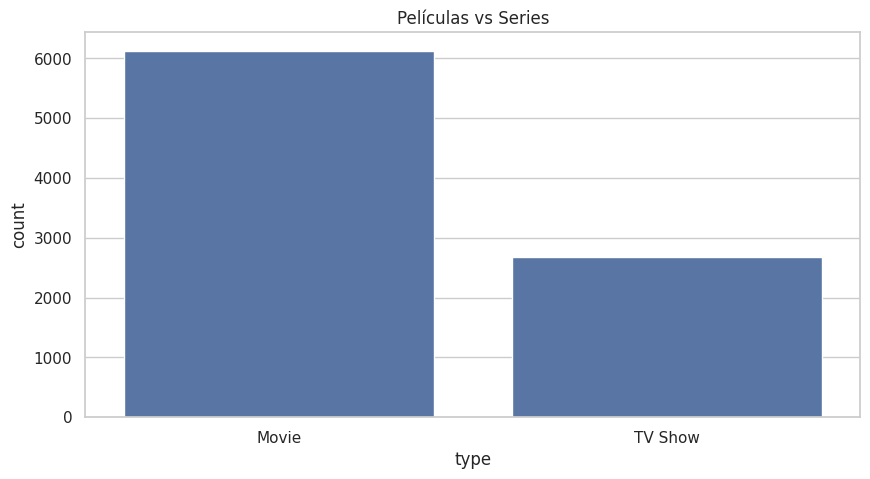

In [24]:
sns.countplot(data=df_jessica, x='type')
plt.title('Películas vs Series')
plt.show()

Se puede observar en el grafico que hay mas peliculas que series en la plataforma\.

###  5 países con mas contenidos generados\.

Contamos cuales son los 5 países que mas contenido genera\.

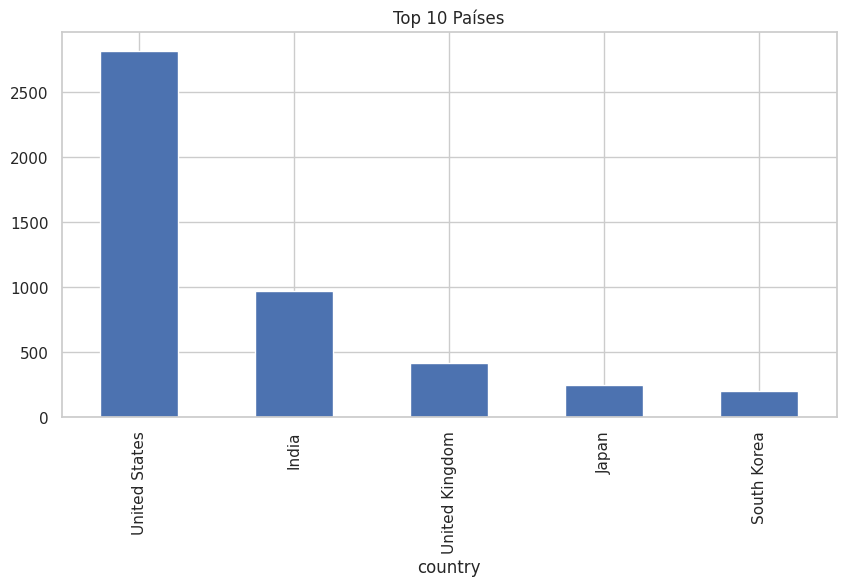

In [25]:
top_paises = df_jessica['country'].value_counts().head(5)
top_paises.plot(kind='bar')
plt.title('Top 10 Países')
plt.show()

Podemos observar que el primer lugar se lo lleva EE\.UU, seguido por India y Reino unido\.

## 3\. Observaciones generales

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

Al analizar los datos, se puede ver que hay mas películas que series\. También se puede observa que Estados Unidos, India y Reino Unido son algunos de los países que más contenido aportan\. Por otro lado estan los datos si bien estan bastante completos notamos que hay algunas columnas como director y reparto que tienen varios datos faltantes\.

# 📁 Dataset 5 – Catálogo E\-commerce Textil y Hogar \(Integrante: Nicolás Galarza Vazquez\)

## 📝 Descripción del Dataset

El dataset contiene información de catálogo comercial y métricas de ventas de productos textiles para el hogar \(edredones, acolchados, sábanas, cortinas\)\. Registra \*\*2\.680 filas y 10 columnas\*\* con datos de precios, medidas, diseños, estado de stock y volumen de ventas mensuales\.

## Importación de Librerías

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## 1\. Carga y exploración de datos

###  Carga vía SQL y Verificación de Requisitos Mínimos

Se realiza la ingesta del archivo mediante la consola SQL integrada de DeepNote y la validación en Python de las dimensiones requeridas \(mínimo 9 columnas y 2\.500 filas\)\.

In [27]:
df_nicolas = pd.read_csv('dataset_ecommerce_hogar_2600.csv')

filas, columnas = df_nicolas.shape
print(f"✅ Filas totales: {filas} | Columnas totales: {columnas}")
display(df_nicolas.head())


✅ Filas totales: 2680 | Columnas totales: 10


,Rubro,Medida,Codigo_Articulo,Diseño,Color,Unidades_Bulto,Estado_Stock,Precio_Publico_ARS,Caracteristica_Piezas,Ventas_Mensuales
0,Funda Almohadón,Twin,ART-931/2,Ginebra,Verde Militar,2,Disponible,48935,Kit de 2 piezas,307
1,Cortinas Ambiente,Twin,ART-927/2,Ginebra,Gris Claro,6,Poco stock,43434,Kit de 3 piezas,337
2,Funda Almohadón,King,ART-957/5,Verona,Azul,3,Disponible,62865,Kit de 7 piezas,179
3,Kit Sábanas,1 1/2 Plazas,ART-913/1,Viena,Beige,4,Disponible,55881,Kit de 5 piezas,314
4,Kit Sábanas,Twin,ART-915/4,Nordic,Negro,1,Poco stock,54803,Kit de 5 piezas,300


📌El dataset cuenta con 2\.680 registros y 10 variables, cumpliendo holgadamente los requisitos técnicos de la materia\.

###  Inspección de Tipos de Datos y Ausencia de Nulos

Evaluación del esquema de datos para verificar la integridad de las columnas numéricas y categóricas\.

In [28]:
print("📊 Tipos de datos por variable:")
print(df_nicolas.dtypes)

print("\n❓ Conteo de valores nulos:")
print(df_nicolas.isnull().sum())

📊 Tipos de datos por variable:
Rubro                    object
Medida                   object
Codigo_Articulo          object
Diseño                   object
Color                    object
Unidades_Bulto            int64
Estado_Stock             object
Precio_Publico_ARS        int64
Caracteristica_Piezas    object
Ventas_Mensuales          int64
dtype: object

❓ Conteo de valores nulos:
Rubro                    0
Medida                   0
Codigo_Articulo          0
Diseño                   0
Color                    0
Unidades_Bulto           0
Estado_Stock             0
Precio_Publico_ARS       0
Caracteristica_Piezas    0
Ventas_Mensuales         0
dtype: int64


📌No se detectaron valores faltantes \(0% nulos\), lo que garantiza un conjunto de datos limpio para iniciar el modelado sin necesidad de imputaciones complejas\.

## 2\. Visualizaciones y análisis

### Distribución de Precios Públicos según el Rubro Comercial

Se analiza el rango de precios de venta al público por cada categoría de producto para identificar los tickets de mayor valor\.

/tmp/ipykernel_540/202117893.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_nicolas, x='Rubro', y='Precio_Publico_ARS', palette='Blues_d')


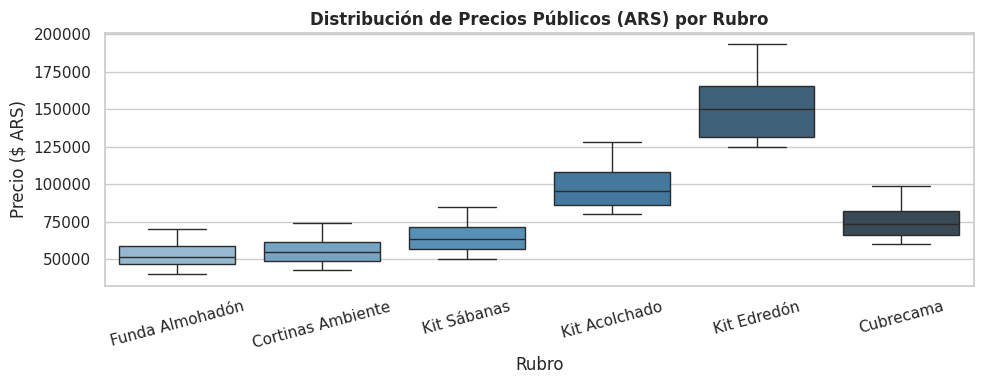

In [29]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_nicolas, x='Rubro', y='Precio_Publico_ARS', palette='Blues_d')
plt.title('Distribución de Precios Públicos (ARS) por Rubro', fontsize=12, fontweight='bold')
plt.xticks(rotation=15)
plt.ylabel('Precio ($ ARS)')
plt.tight_layout()
plt.show()

📌 Los \*Kits de Edredones\* y \*Kits de Acolchados\* presentan los precios más elevados \(entre $85\.000 y $160\.000 ARS\), mientras que las \*Fundas de Almohadón\* y \*Cortinas\* ocupan el segmento de entrada\. Se observa una dispersión uniforme asociada a las distintas medidas \(Queen/King vs\. Twin\)\.

### Promedio de Ventas Mensuales por Estado de Stock

Se evalúa el volumen medio de ventas mensuales asociadas a la disponibilidad del producto en inventario\.

/tmp/ipykernel_540/3521418872.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_nicolas, x='Estado_Stock', y='Ventas_Mensuales', estimator=np.mean, errorbar=None, palette='Blues_r')


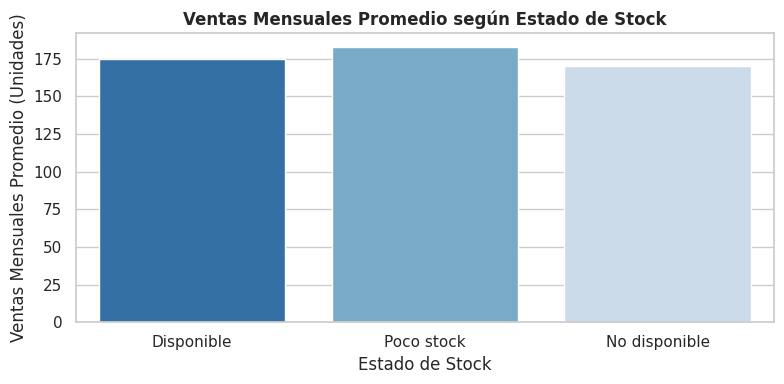

In [30]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df_nicolas, x='Estado_Stock', y='Ventas_Mensuales', estimator=np.mean, errorbar=None, palette='Blues_r')
plt.title('Ventas Mensuales Promedio según Estado de Stock', fontsize=12, fontweight='bold')
plt.xlabel('Estado de Stock')
plt.ylabel('Ventas Mensuales Promedio (Unidades)')
plt.tight_layout()
plt.show()

📌 Los productos clasificados como "Poco stock" o "Disponible" registran el mayor promedio de unidades vendidas al mes, indicando que los artículos de alta rotación corren riesgo de quiebre de inventario si no se reabastecen a tiempo\.

## 3\. Observaciones generales

\- Patrones observados: Existe una clara segmentación de precios impulsada por el \*Rubro\* y la \*Medida\*, y una alta rotación en productos con bajo stock\.
\- Calidad de datos: Excelente calidad con 2\.680 observaciones completas sin nulos\.
\- Variables de mayor interés: \`Precio\_Publico\_ARS\`, \`Ventas\_Mensuales\`, \`Rubro\` y \`Estado\_Stock\` resultan sumamente prometedoras para construir un modelo predictivo de demandas o un clasificador de riesgo de stock en las entregas 2 y 3\.

# ✅ Conclusión del equipo

Después de analizar todos los datasets, el equipo ha decidido continuar el trabajo con el dataset:

## 🏆 Dataset elegido: Dataset 4 – netflix\_titles\.csv

## 📌 Motivos de la elección:

- Es el más completo en cuanto a variables y registros\.

- Tiene información actualizada/relevante para una problemática interesante\.

- Se visualiza potencial para aplicar técnicas de IA en próximas etapas \(clasificación, predicción, clustering, etc\.\)\.

- Es una temática muy cercana y cotidiana para todos, lo que hace que los datos sean fáciles de entender, el análisis sea entretenido y nos resulte más simple validar si las conclusiones tienen sentido\.

- Permite responder preguntas muy interesantes y visuales sobre la industria del entretenimiento, como ver la evolución del catálogo a lo largo de los años, qué géneros predominan o la relación entre series y películas\.

- Tiene una gran diversidad de datos de texto y categorías \(géneros, países, actores, clasificaciones\) que nos dan mucho margen para agrupar contenido y comparar distintas variables\.

- Al ser datos de una plataforma que todos conocemos \(películas, series, actores, países\), nos resulta intuitivo de analizar y facilita la interpretación de los resultados\.

## 💡 Próximos pasos

- Limpieza y preparación del dataset elegido\.

- Diseño de una solución basada en la problemática detectada\.

- Implementación y validación del modelo\.

# SEGUNDA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Análisis EDA \(según lo trabajaron en la entrega 1\)
Análisis univariado, bivariado y/o multivariado
4 hipótesis sobre el dataset
Gráficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.

## 🔍 Introducción

Vamos a \.\.\.

# 📁 Dataset seleccionado– \[Nombre del dataset\] 

## 📝 Descripción del Dataset

Describir de que se trata el dataset

## Importación de Librerías

In [31]:
#Importación de librerías

## 1\. Carga y exploración de datos

###  \[Nombre de la acción\]

Introducción a la acción

In [32]:
# Código para cargar el dataset y mostrar estructura

Interpretación de la acción

###  \[Nombre de la acción\]

Introducción a la acción

In [33]:
# Código para analizar el dataset y mostrar estructura

Interpretación de la acción

## 2\. Limpieza de Datos

## Analisis Univariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [34]:
#Gráfico 1

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## 3\. Visualizaciones y análisis

## Analisis Univariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [35]:
#Gráfico 1

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## Analisis Bivariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [36]:
#Gráfico 1

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 2

In [37]:
#Gráfico 2

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 3

In [38]:
#Gráfico 3

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## Analisis Multivariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [39]:
#Gráfico 1

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 2

In [40]:
#Gráfico 2

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 3

In [41]:
#Gráfico 3

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## 4\. Planteo de Hipótesis

###  \[Hipótesis 1\]

Introducción Hipótesis  

In [42]:
#desarrollo Hipótesis 

In [43]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 2\]

Introducción Hipótesis  

In [44]:
#desarrollo Hipótesis 

In [45]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 3\]

Introducción Hipótesis  

In [46]:
#desarrollo Hipótesis 

In [47]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 4\]

Introducción Hipótesis  

In [48]:
#desarrollo Hipótesis 

In [49]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

### \[Hipótesis 2\]

# ✅ Conclusión del equipo

Hemos podido observar que\.\.\.

# TERCERA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Introducción y descripción del dataset
Planteamiento del objetivo del proyecto
Planteamiento de hipótesis y resumen de las conclusiones sobre las hipótesis
Análisis EDA
Análisis univariado
Análisis Bivariado y/o multivariado
Graficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.
Aplicación de modelos de Regresión,
Clasificación o Agrupación según lo planteado en el objetivo\.
\(mínimo 3 modelos\)
Métricas de evaluación del modelo aplicado
Selección del modelo más indicado en base a las métricas\.

## 🔍 Introducción 

# 📁 Dataset elegido – \[Nombre del dataset\] 

## 📝 Descripción del Dataset

Describir de que se trata el dataset

## Importación de Librerías

In [50]:
#Importación de librerías

## 1\. Carga y exploración de datos

###  \[Nombre de la acción\]

Introducción a la acción

In [51]:
# Código para cargar el dataset y mostrar estructura

Interpretación de la acción

###  \[Nombre de la acción\]

Introducción a la acción

In [52]:
# Código para analizar el dataset y mostrar estructura

Interpretación de la acción

## 2\. Visualizaciones y análisis

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [53]:
#Gráfico 1

📌 Interpretación del gráfico

Introducción al Gráfico 2

In [54]:
#Gráfico 2

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

# ✅ Conclusión del equipo

Después de analizar todos los datasets, el equipo ha decidido continuar el trabajo con el dataset:

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=a78743f6-4233-415c-b256-c7edf51a9ef0' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>